# Music Genre Classification with a Custom CNN

This is the second approach after the classical MFCC + Random Forest baseline. We use raw FMA-Small recordings: 8,000 tracks, 8 genres, and the official 6,400/800/800 train/validation/test splits. See the [README](../README.md) for the data source and licensing information.

Inputs are log-Mel segments: mono audio, 22,050 Hz, 3 seconds, 128 Mel bins, FFT size 2,048, and hop length 512. All segments of a track remain in its official split. Training, validation, and test sets share the same class mapping.

This notebook contains no precomputed results. Generate the plots by running training, then write conclusions based on the observed results.


In [1]:
import sys
from pathlib import Path
from time import perf_counter

project_root = Path.cwd()
if not (project_root / "src").is_dir():
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from sklearn.ensemble import RandomForestClassifier
from sklearn.manifold import TSNE
from sklearn.metrics import accuracy_score, f1_score
from torch.utils.data import DataLoader

from src.audio_classification.data import (
    FMASpectrogramDataset,
    collate_spectrograms,
    load_fma_metadata,
)
from src.audio_classification.evaluate import evaluate_model, grad_cam
from src.audio_classification.models import AudioCNN
from src.audio_classification.prepare_data import prepare_spectrogram_cache
from src.audio_classification.train import train_model
from src.audio_classification.utils import set_seed

SEED = 42
set_seed(SEED)

Global seed set to: 42


## Configuration and Data

Start with `SMALL_RUN = True`: 80 training tracks, 40 validation tracks, and 3 epochs. Set `SMALL_RUN = False` for the full dataset; this uses a separate checkpoint and a limit of 30 epochs.

The GPU is selected when PyTorch provides CUDA support. A PyTorch build marked `+cpu` runs on the CPU. MP3 decoding runs in parallel on the CPU; resampling and batched log-Mel transforms use the selected device. Existing spectrograms are reused. Missing or invalid entries are prepared before training, and training loads cached tensors only. The full cache requires approximately 5 GB. Change the cache directory name when changing spectrogram parameters.

MLflow stores parameters and results in a local SQLite database at `mlruns/mlflow.db`. After installing the dependencies, launch the interface from the project root: `mlflow ui --backend-store-uri sqlite:///mlruns/mlflow.db`.

Decoder failures are listed in the cache directory in `preprocessing_report.json` and excluded explicitly. The same exclusions are applied to the Random Forest comparison. Previously failed files are retried only with `retry_failed=True` when calling `prepare_spectrogram_cache`. Infrastructure errors are not treated as bad recordings.

`classical_train.npy` and `classical_val.npy` contain 44 descriptors per track for Random Forest; they cannot replace the two-dimensional spectrogram input required by this CNN.

CUDA training uses automatic mixed precision, 8 tracks per batch and 2 persistent DataLoader workers with prefetching. CPU training uses full precision. Adjust `BATCH_SIZE` for the available GPU memory and `NUM_WORKERS` for the CPU.


In [2]:
SMALL_RUN = False
EVALUATE_TEST = False
BATCH_SIZE = 8
NUM_WORKERS = 2
PREPARE_WORKERS = 4
USE_AMP = True
EPOCHS = 3 if SMALL_RUN else 30

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
run_name = "cnn_small_cached_amp" if SMALL_RUN else "cnn_full_cached_amp"
checkpoint_path = project_root / "models" / f"{run_name}.pt"
processed_dir = project_root / "data" / "processed"
cache_dir = processed_dir / "logmel_sr22050_fft2048_hop512_m128_s3_v1"
figures_dir = project_root / "reports" / "figures" / run_name
figures_dir.mkdir(parents=True, exist_ok=True)
tracking_dir = project_root / "mlruns"
tracking_dir.mkdir(parents=True, exist_ok=True)
mlflow.set_tracking_uri(f"sqlite:///{(tracking_dir / 'mlflow.db').as_posix()}")
if mlflow.get_experiment_by_name("fma-small") is None:
    mlflow.create_experiment(
        "fma-small", artifact_location=(tracking_dir / "artifacts").as_uri()
    )
mlflow.set_experiment("fma-small")

metadata_df = load_fma_metadata(str(project_root / "data" / "raw" / "fma_metadata"))
df = metadata_df.copy()
if not EVALUATE_TEST:
    df = df[df["split"] != "test"].copy()
if SMALL_RUN:
    df = pd.concat(
        [
            df[df["split"] == split].groupby("genre").sample(n=count, random_state=SEED)
            for split, count in (("training", 10), ("validation", 5))
        ],
        ignore_index=True,
    )

# Finish preprocessing before training so batches never decode MP3 files.
df, preprocessing_report = prepare_spectrogram_cache(
    df,
    audio_dir=project_root / "data" / "raw" / "fma_small",
    cache_dir=cache_dir,
    device=device,
    num_workers=PREPARE_WORKERS,
)
print("Excluded tracks:", len(preprocessing_report["excluded"]))
print("Preprocessing report:", cache_dir / "preprocessing_report.json")

train_dataset = FMASpectrogramDataset(
    df,
    audio_dir=str(project_root / "data" / "raw" / "fma_small"),
    target_split="training",
    cache_dir=str(cache_dir),
    cache_only=True,
)
val_dataset = FMASpectrogramDataset(
    df,
    audio_dir=str(project_root / "data" / "raw" / "fma_small"),
    target_split="validation",
    cache_dir=str(cache_dir),
    cache_only=True,
)
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_spectrograms,
    generator=torch.Generator().manual_seed(SEED),
    num_workers=NUM_WORKERS,
    persistent_workers=NUM_WORKERS > 0,
    prefetch_factor=2 if NUM_WORKERS > 0 else None,
    pin_memory=device.type == "cuda",
)
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_spectrograms,
    num_workers=NUM_WORKERS,
    persistent_workers=NUM_WORKERS > 0,
    prefetch_factor=2 if NUM_WORKERS > 0 else None,
    pin_memory=device.type == "cuda",
)
print("Device:", device)
print("Tracks:", len(train_dataset), len(val_dataset))
print("Genres:", train_dataset.genre_to_idx)

Spectrogram cache: 1/7200, reused=0, created=1, excluded=0
Spectrogram cache: 100/7200, reused=11, created=89, excluded=0
Spectrogram cache: 200/7200, reused=20, created=180, excluded=0
Spectrogram cache: 300/7200, reused=34, created=266, excluded=0
Spectrogram cache: 400/7200, reused=47, created=353, excluded=0
Spectrogram cache: 500/7200, reused=60, created=440, excluded=0
Spectrogram cache: 600/7200, reused=77, created=523, excluded=0
Spectrogram cache: 700/7200, reused=93, created=607, excluded=0
Spectrogram cache: 800/7200, reused=105, created=695, excluded=0
Spectrogram cache: 900/7200, reused=121, created=779, excluded=0
Spectrogram cache: 1000/7200, reused=135, created=865, excluded=0
Spectrogram cache: 1100/7200, reused=155, created=945, excluded=0
Spectrogram cache: 1200/7200, reused=173, created=1027, excluded=0
Spectrogram cache: 1300/7200, reused=185, created=1115, excluded=0
Spectrogram cache: 1400/7200, reused=196, created=1204, excluded=0
Spectrogram cache: 1500/7200, r

## Model and Training

The CNN contains four Conv2d-BatchNorm-ReLU-MaxPool blocks, global pooling, a 512-dimensional embedding, and a classifier. Each segment is normalized independently, without fitting normalization statistics on validation or test data.

The loss is segment cross-entropy averaged first within each track and then across tracks. Adam uses a learning rate of 0.001 and weight decay of 0.0001. The best checkpoint is selected by validation macro-F1; early stopping uses a patience of 5 epochs. MLflow also records the track IDs assigned to each split.

An existing checkpoint is loaded automatically. Change `run_name` and the checkpoint path to start a new experiment.

CUDA forward passes use mixed precision with gradient scaling; loss and track-level metrics are calculated in float32. Grad-CAM remains in full precision. The preprocessing exclusion report is stored with each training run in MLflow.


Global seed set to: 42
Epoch 1/30
  100/800 training batches
  200/800 training batches
  300/800 training batches
  400/800 training batches
  500/800 training batches
  600/800 training batches
  700/800 training batches
  800/800 training batches
Epoch 1/30: train_loss=1.7856, val_loss=1.8693, val_macro_f1=0.2587
Epoch 2/30
  100/800 training batches
  200/800 training batches
  300/800 training batches
  400/800 training batches
  500/800 training batches
  600/800 training batches
  700/800 training batches
  800/800 training batches
Epoch 2/30: train_loss=1.6241, val_loss=1.6432, val_macro_f1=0.4548
Epoch 3/30
  100/800 training batches
  200/800 training batches
  300/800 training batches
  400/800 training batches
  500/800 training batches
  600/800 training batches
  700/800 training batches
  800/800 training batches
Epoch 3/30: train_loss=1.5592, val_loss=1.5386, val_macro_f1=0.4477
Epoch 4/30
  100/800 training batches
  200/800 training batches
  300/800 training batches


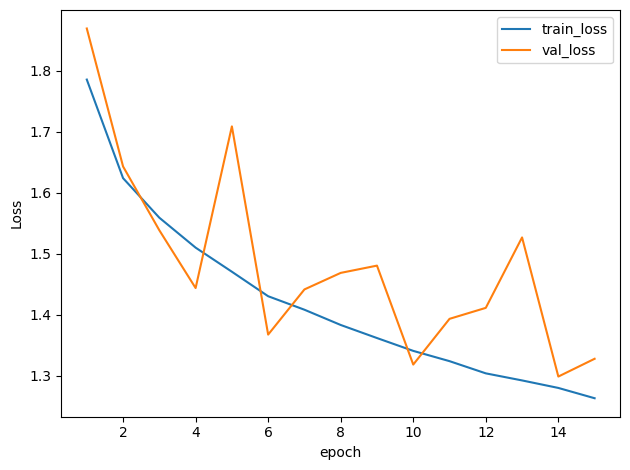

Best epoch: 10
Training seconds: 536.4273777999915


In [3]:
if checkpoint_path.exists():
    checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
    if checkpoint["genres"] != train_dataset.genres:
        raise ValueError("Checkpoint class mapping differs from the dataset")
    model = AudioCNN(**checkpoint["model_config"]).to(device)
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()
    print("Loaded checkpoint:", checkpoint_path)
else:
    model = AudioCNN(num_classes=len(train_dataset.genres)).to(device)
    checkpoint = train_model(
        model,
        train_loader,
        val_loader,
        device,
        checkpoint_path,
        epochs=EPOCHS,
        seed=SEED,
        use_amp=USE_AMP,
        data_report=preprocessing_report,
    )

history = pd.DataFrame(checkpoint["history"]).set_index("epoch")
history[["train_loss", "val_loss"]].plot()
plt.ylabel("Loss")
plt.tight_layout()
plt.savefig(figures_dir / "learning_curves.png")
plt.show()
print("Best epoch:", checkpoint["best_epoch"])
print("Training seconds:", checkpoint["training_seconds"])

## Validation and Model Comparison

Track predictions are obtained by averaging probabilities across their segments. The report includes accuracy, macro-F1, per-class precision/recall/F1, and a confusion matrix.

Comparison with Random Forest runs only in full-dataset mode, after notebook 02 has saved `classical_train.npy` and `classical_val.npy`. CNN inference time includes fetching data through the DataLoader. The baseline training time recorded in MLflow excludes the earlier feature extraction.


               precision  recall  f1-score  support
Electronic      0.528846    0.55  0.539216   100.00
Experimental    0.475524    0.68  0.559671   100.00
Folk            0.709677    0.88  0.785714   100.00
Hip-Hop         0.569343    0.78  0.658228   100.00
Instrumental    0.584158    0.59  0.587065   100.00
International   0.820513    0.64  0.719101   100.00
Pop             0.250000    0.06  0.096774   100.00
Rock            0.786517    0.70  0.740741   100.00
accuracy        0.610000    0.61  0.610000     0.61
macro avg       0.590572    0.61  0.585814   800.00
weighted avg    0.590572    0.61  0.585814   800.00
Inference seconds: 1.5613549000117928


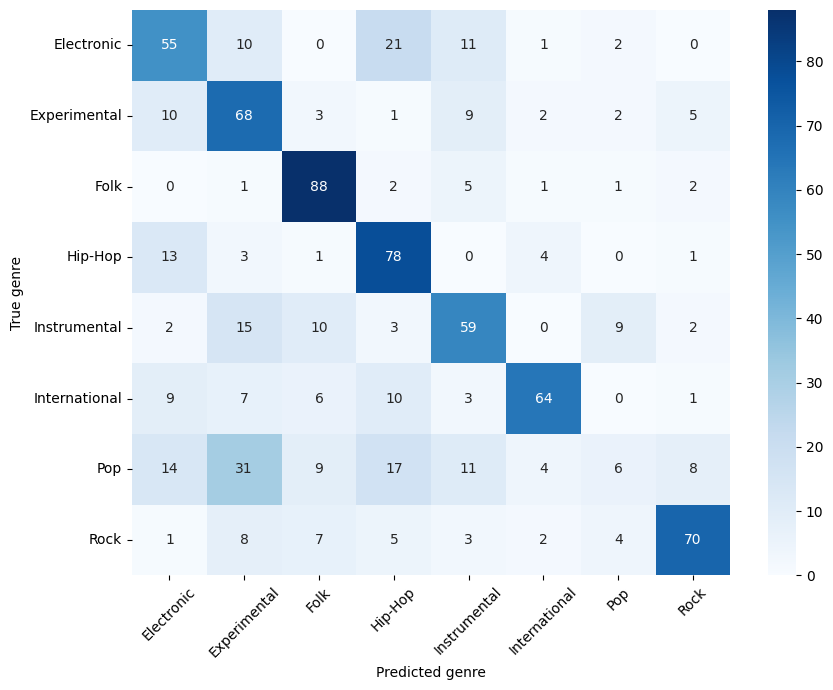

                  model  accuracy  macro_f1
0              AudioCNN   0.61000  0.585814
1  MFCC + Random Forest   0.50625  0.495067


In [4]:
validation = evaluate_model(model, val_loader, device, use_amp=USE_AMP)
print(pd.DataFrame(validation["report"]).T)
print("Inference seconds:", validation["inference_seconds"])

plt.figure(figsize=(9, 7))
sns.heatmap(
    validation["confusion_matrix"],
    annot=True,
    fmt="d",
    xticklabels=val_dataset.genres,
    yticklabels=val_dataset.genres,
    cmap="Blues",
)
plt.xlabel("Predicted genre")
plt.ylabel("True genre")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(figures_dir / "confusion_matrix.png")
plt.show()

rows = [
    {
        "model": "AudioCNN",
        "accuracy": validation["accuracy"],
        "macro_f1": validation["macro_f1"],
    }
]
train_features_path = processed_dir / "classical_train.npy"
val_features_path = processed_dir / "classical_val.npy"
if not SMALL_RUN and train_features_path.exists() and val_features_path.exists():
    X_train = np.load(train_features_path, allow_pickle=False)
    X_val = np.load(val_features_path, allow_pickle=False)
    full_train = metadata_df[metadata_df["split"] == "training"]
    full_val = metadata_df[metadata_df["split"] == "validation"]
    if len(X_train) != len(full_train) or len(X_val) != len(full_val):
        raise ValueError("Baseline cache does not match the full data splits")
    # Apply the same explicit exclusions to both models.
    train_positions = pd.Index(full_train["track_id"]).get_indexer(
        train_dataset.df["track_id"]
    )
    val_positions = pd.Index(full_val["track_id"]).get_indexer(
        val_dataset.df["track_id"]
    )
    if (train_positions < 0).any() or (val_positions < 0).any():
        raise ValueError("CNN track IDs are missing from baseline metadata")
    X_train = X_train[train_positions]
    X_val = X_val[val_positions]
    baseline = RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1)
    started = perf_counter()
    baseline.fit(X_train, train_dataset.df["genre"].values)
    baseline_training_seconds = perf_counter() - started
    baseline_pred = baseline.predict(X_val)
    baseline_metrics = {
        "accuracy": float(
            accuracy_score(val_dataset.df["genre"].values, baseline_pred)
        ),
        "macro_f1": float(
            f1_score(
                val_dataset.df["genre"].values,
                baseline_pred,
                labels=val_dataset.genres,
                average="macro",
                zero_division=0,
            )
        ),
    }
    rows.append({"model": "MFCC + Random Forest", **baseline_metrics})
    with mlflow.start_run(run_name="random_forest_baseline"):
        mlflow.log_params(
            {
                "n_estimators": 100,
                "seed": SEED,
                "features": "44 cached classical audio features",
                "train_tracks": len(train_dataset),
                "validation_tracks": len(val_dataset),
            }
        )
        mlflow.log_metrics(
            {
                **baseline_metrics,
                "training_seconds_without_feature_extraction": (
                    baseline_training_seconds
                ),
            }
        )

comparison = pd.DataFrame(rows)
comparison.to_csv(figures_dir / "validation_comparison.csv", index=False)
print(comparison)

## Embeddings, Interpretability, and Error Analysis

Normalized 512-dimensional embeddings are saved in `data/processed` together with track IDs, labels, and class order. A t-SNE projection provides a global view of their structure.

[Grad-CAM](https://arxiv.org/abs/1610.02391) is computed for the whole-track prediction. We display the segment with the highest probability for the predicted class, separately for a correct and an incorrect prediction when such examples are available.

After training, write 2-3 sentences for the projection and each heatmap: identify confused classes, explain which time-frequency regions support the prediction, and consider whether recording artifacts could explain those patterns.


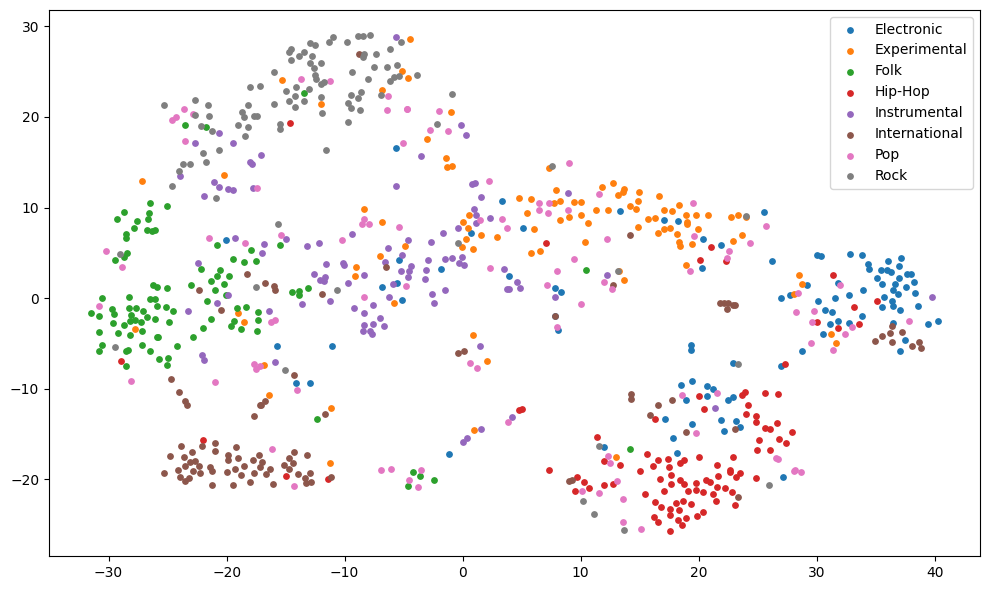

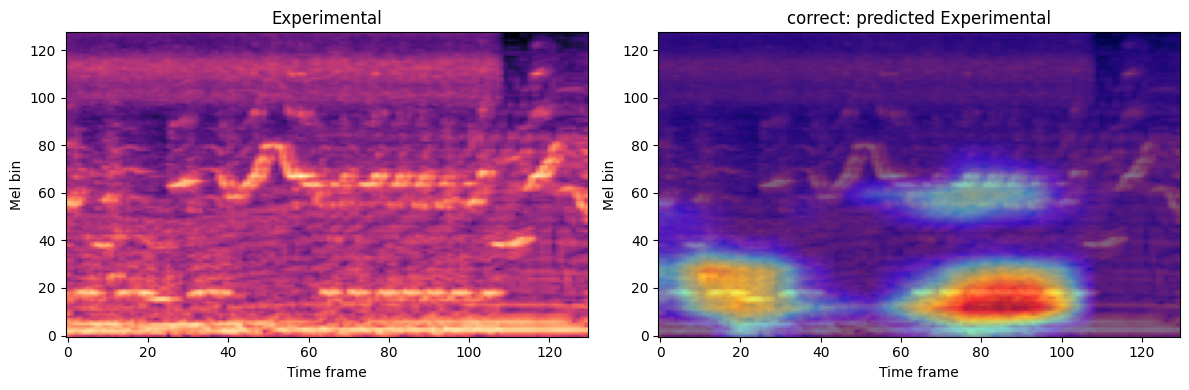

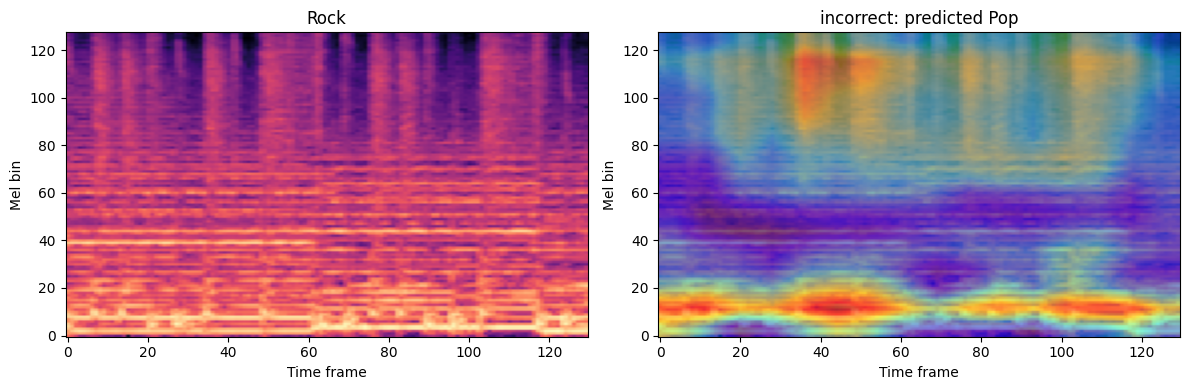

In [5]:
embeddings = validation["embeddings"]
embeddings = embeddings / np.maximum(
    np.linalg.norm(embeddings, axis=1, keepdims=True), 1e-12
)
embedding_path = processed_dir / f"{run_name}_validation_embeddings.npz"
np.savez_compressed(
    embedding_path,
    embeddings=embeddings,
    track_ids=val_dataset.df["track_id"].to_numpy(),
    labels=validation["y_true"],
    genres=np.asarray(val_dataset.genres, dtype=str),
)
projection = TSNE(
    n_components=2,
    perplexity=min(30, len(embeddings) - 1),
    random_state=SEED,
).fit_transform(embeddings)
plt.figure(figsize=(10, 6))
for class_index, genre in enumerate(val_dataset.genres):
    selected = validation["y_true"] == class_index
    plt.scatter(
        projection[selected, 0],
        projection[selected, 1],
        label=genre,
        s=15,
    )
plt.legend()
plt.tight_layout()
plt.savefig(figures_dir / "embedding_tsne.png")
plt.show()

correct = validation["y_true"] == validation["y_pred"]
for name, indices in (
    ("correct", np.flatnonzero(correct)),
    ("incorrect", np.flatnonzero(~correct)),
):
    if not len(indices):
        print("No examples:", name)
        continue
    index = int(indices[0])
    specs, label = val_dataset[index]
    target = int(validation["y_pred"][index])
    heatmaps, segment_probs = grad_cam(model, specs, target, device)
    segment = int(segment_probs[:, target].argmax())
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax in axes:
        ax.imshow(
            specs[segment, 0].numpy(),
            origin="lower",
            aspect="auto",
            cmap="magma",
        )
        ax.set_xlabel("Time frame")
        ax.set_ylabel("Mel bin")
    axes[0].set_title(val_dataset.genres[int(label)])
    axes[1].imshow(
        heatmaps[segment].numpy(),
        origin="lower",
        aspect="auto",
        cmap="jet",
        alpha=0.5,
    )
    axes[1].set_title(f"{name}: predicted {val_dataset.genres[target]}")
    fig.tight_layout()
    fig.savefig(figures_dir / f"gradcam_{name}.png")
    plt.show()

## Saving the Analysis and Final Evaluation

Validation results, figures, and embeddings are logged to the MLflow run associated with the checkpoint.

Keep `EVALUATE_TEST = False` during model selection. Set it to `True` only after completing the experiments, in full-dataset mode. The test set is not used for training, early stopping, or checkpoint selection.


In [6]:
with mlflow.start_run(run_id=checkpoint["run_id"]):
    mlflow.log_metrics(
        {
            f"best_validation_{key}": validation[key]
            for key in ("loss", "accuracy", "macro_f1", "inference_seconds")
        }
    )
    mlflow.log_dict(validation["report"], "validation_report.json")
    mlflow.log_artifacts(str(figures_dir), artifact_path="evaluation")
    mlflow.log_artifact(str(embedding_path), artifact_path="embeddings")

    if EVALUATE_TEST and not SMALL_RUN:
        test_dataset = FMASpectrogramDataset(
            df,
            audio_dir=str(project_root / "data" / "raw" / "fma_small"),
            target_split="test",
            cache_dir=str(cache_dir),
            cache_only=True,
        )
        test_loader = DataLoader(
            test_dataset,
            batch_size=BATCH_SIZE,
            shuffle=False,
            collate_fn=collate_spectrograms,
            num_workers=NUM_WORKERS,
            persistent_workers=NUM_WORKERS > 0,
            prefetch_factor=2 if NUM_WORKERS > 0 else None,
            pin_memory=device.type == "cuda",
        )
        test_result = evaluate_model(model, test_loader, device, use_amp=USE_AMP)
        mlflow.log_metrics(
            {
                f"test_{key}": test_result[key]
                for key in ("loss", "accuracy", "macro_f1", "inference_seconds")
            }
        )
        mlflow.log_dict(test_result["report"], "test_report.json")
        print(pd.DataFrame(test_result["report"]).T)

## Conclusions

The CNN achieved 61.00% accuracy and 0.586 macro-F1 on 800 validation tracks, compared with 50.63% and 0.495 for MFCC + Random Forest on the same tracks. This improves accuracy by 10.38 percentage points and macro-F1 by 0.091.

The learning curves show decreasing training loss but fluctuating validation loss. The best validation macro-F1 occurred at epoch 10; early stopping ended training at epoch 15 and restored that checkpoint. CUDA training with mixed precision took 536.4 seconds, excluding cache preparation; validation inference, including data loading, took 1.56 seconds.

The confusion matrix shows the strongest F1 scores for Folk (0.786), Rock (0.741), and International (0.719). Pop is the main weakness: only 6 of 100 tracks were recognized, giving an F1 of 0.097; 31 were classified as Experimental, 17 as Hip-Hop, and 14 as Electronic.

The t-SNE projection shows visible concentrations of Folk, Rock, and International embeddings, while Pop is scattered among other genres. This is consistent with the classification results, but a two-dimensional projection alone does not validate the quality of sounds-like retrieval.

For the correctly classified Experimental example, Grad-CAM highlights localized regions mainly in the lower Mel bins, with another region in the middle bins. These regions support the model's predicted-class score, but the visualization does not establish which instruments or musical properties caused the decision.

For the Rock track incorrectly classified as Pop, Grad-CAM highlights low-frequency bands and broader regions in the upper Mel bins. These patterns did not lead to the correct genre prediction; the heatmap alone cannot determine whether musical overlap or recording artifacts explain the error.

Training used 6,394 tracks after explicitly excluding three decoding failures and three missing files; the Random Forest comparison used the same exclusions. Genre overlap, recording quality, and the limited context of three-second segments remain possible limitations, and averaging segment probabilities does not model long-term musical structure.

The next priority is to inspect misclassified Pop tracks and compare their predictions with the baseline. These are validation results only: the test set remains unevaluated and should be used after model selection is complete.
